# CU-BEMS Floor 6 Zone 1/2/4/5 Data Preparation and EDA

本 notebook 针对 CU-BEMS 数据集进行重新优化：仅选取 **2018 年 Floor 6**，并使用 **Zone 1、Zone 2、Zone 4、Zone 5** 作为主要分析对象。

处理目标：

- 每个 selected Zone 的 AC 设备按时间点在 Zone 内求和，形成单一 `total_AC_power_kw`。
- 原始 individual AC 设备列不进入最终建模表。
- Zone 1、Zone 2、Zone 4、Zone 5 统一成纵向 long format。
- 分析范围限定为 **2018-07-01 至 2018-09-01 23:59:00**。
- 进行数据质量检查、rolling mean 平滑和 EDA，为后续 anomaly detection 建立数据基础。

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

plt.style.use("default")

## 1. Configuration

In [2]:
FLOOR = 6
YEARS = [2018]
SELECTED_ZONES = [1, 2, 4, 5]

ANALYSIS_START = pd.Timestamp("2018-07-01 00:00:00")
ANALYSIS_END = pd.Timestamp("2018-09-01 23:59:00")

ROLLING_WINDOW_RECORDS = 15
ROLLING_MIN_PERIODS = 5

VALUE_COLUMNS = [
    "total_AC_power_kw",
    "light_power_kw",
    "plug_power_kw",
    "temperature_c",
    "humidity_pct",
    "lux",
]
POWER_COLUMNS = ["total_AC_power_kw", "light_power_kw", "plug_power_kw"]
COMPONENT_POWER_COLUMNS = ["total_AC_power_kw", "light_power_kw", "plug_power_kw"]
ENVIRONMENT_COLUMNS = ["temperature_c", "humidity_pct", "lux"]
KEY_COLUMNS = ["timestamp", "floor", "zone"]

NOTEBOOK_CWD = Path.cwd()
RAW_DATA_CANDIDATES = [
    NOTEBOOK_CWD / "Raw Data",
    NOTEBOOK_CWD / "Artificial Intelligence for Smart-Building Log Analysis" / "Raw Data",
    NOTEBOOK_CWD.parent / "Raw Data",
]
RAW_DATA_DIR = next((path for path in RAW_DATA_CANDIDATES if path.exists()), None)
if RAW_DATA_DIR is None:
    raise FileNotFoundError("Could not locate the Raw Data directory.")

PROJECT_DIR = RAW_DATA_DIR.parent
OUTPUT_DIR = PROJECT_DIR / "outputs" / "floor6_zone1245_2018_jul01_sep01_total_ac_eda"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "eda_tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

FINAL_DATASET = OUTPUT_DIR / "floor6_zone1245_cleaned_smoothed_2018_jul01_sep01.csv.gz"

print("Raw data directory:", RAW_DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Figure directory:", FIGURE_DIR)

Raw data directory: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/Raw Data
Output directory: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda
Figure directory: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures


## 2. Floor 6 Zone Schema

In [3]:
AC_COLUMN_PATTERN = re.compile(r"^z(?P<zone>\d+)_AC(?P<meter>\d+)\(kW\)$")
AC_TOTAL_COLUMN_TEMPLATE = "z{zone}_AC_total(kW)"

ZONE_SPECS = {
    1: {
        "light_col": "z1_Light(kW)",
        "plug_col": "z1_Plug(kW)",
        "temperature_col": "z1_S1(degC)",
        "humidity_col": "z1_S1(RH%)",
        "lux_col": "z1_S1(lux)",
    },
    2: {
        "light_col": "z2_Light(kW)",
        "plug_col": "z2_Plug(kW)",
        "temperature_col": "z2_S1(degC)",
        "humidity_col": "z2_S1(RH%)",
        "lux_col": "z2_S1(lux)",
    },
    4: {
        "light_col": "z4_Light(kW)",
        "plug_col": "z4_Plug(kW)",
        "temperature_col": "z4_S1(degC)",
        "humidity_col": "z4_S1(RH%)",
        "lux_col": "z4_S1(lux)",
    },
    5: {
        "light_col": "z5_Light(kW)",
        "plug_col": "z5_Plug(kW)",
        "temperature_col": "z5_S1(degC)",
        "humidity_col": "z5_S1(RH%)",
        "lux_col": "z5_S1(lux)",
    },
}

required_columns = {"Date"}
for spec in ZONE_SPECS.values():
    required_columns.update([spec["light_col"], spec["plug_col"], spec["temperature_col"], spec["humidity_col"], spec["lux_col"]])

print("Selected zones:", SELECTED_ZONES)
print("AC column detection pattern:", AC_COLUMN_PATTERN.pattern)
print("Required non-AC raw columns:", len(required_columns))

Selected zones: [1, 2, 4, 5]
AC column detection pattern: ^z(?P<zone>\d+)_AC(?P<meter>\d+)\(kW\)$
Required non-AC raw columns: 21


## 3. Load Raw Data

In [4]:
def load_floor_raw_data(raw_data_dir: Path, floor: int, years: list[int], required_cols: set[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    parts = []
    audit_rows = []

    for year in years:
        file_path = raw_data_dir / f"{year}Floor{floor}.csv"
        raw = pd.read_csv(file_path)
        missing_required = sorted(required_cols.difference(raw.columns))
        if missing_required:
            raise ValueError(f"{file_path.name} is missing required columns: {missing_required}")

        raw.insert(0, "source_file", file_path.name)
        raw.insert(0, "floor", floor)
        raw.insert(0, "year", year)
        raw["timestamp"] = pd.to_datetime(raw["Date"], format="%d/%m/%Y %H:%M", errors="coerce")

        audit_rows.append({
            "year": year,
            "file_name": file_path.name,
            "rows": len(raw),
            "columns": len(raw.columns),
            "invalid_timestamp_rows": int(raw["timestamp"].isna().sum()),
            "min_timestamp": raw["timestamp"].min(),
            "max_timestamp": raw["timestamp"].max(),
        })
        parts.append(raw)

    return pd.concat(parts, ignore_index=True), pd.DataFrame(audit_rows)

raw_wide, load_audit = load_floor_raw_data(RAW_DATA_DIR, FLOOR, YEARS, required_columns)
load_audit.to_csv(OUTPUT_DIR / "01_load_audit_floor6.csv", index=False)

display(load_audit.head(20))
display(raw_wide.head(20))
print("Combined raw rows:", f"{len(raw_wide):,}")
print("Combined raw columns:", len(raw_wide.columns))

,year,file_name,rows,columns,invalid_timestamp_rows,min_timestamp,max_timestamp
0,2018,2018Floor6.csv,264960,34,0,2018-07-01,2018-12-31 23:59:00


,year,floor,source_file,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_AC1(kW),z4_AC2(kW),z4_AC3(kW),z4_AC4(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),timestamp
0,2018,6,2018Floor6.csv,1/07/2018 0:00,0.0,0.0,0.31,27.57,72.19,0.0,0.0,0.01,0.13,27.79,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:00:00
1,2018,6,2018Floor6.csv,1/07/2018 0:01,0.0,0.0,0.31,27.57,72.18,0.0,0.0,0.01,0.13,27.78,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.06,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:01:00
2,2018,6,2018Floor6.csv,1/07/2018 0:02,0.0,0.0,0.31,27.57,72.18,0.0,0.0,0.01,0.13,27.77,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.11,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.50,0.0,2018-07-01 00:02:00
3,2018,6,2018Floor6.csv,1/07/2018 0:03,0.0,0.0,0.26,27.56,72.17,0.0,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.22,27.27,71.76,0.0,0.0,0.0,0.01,28.9,68.51,0.0,2018-07-01 00:03:00
4,2018,6,2018Floor6.csv,1/07/2018 0:04,0.0,0.0,0.26,27.56,72.17,0.0,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.21,27.27,71.76,0.0,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:04:00
5,2018,6,2018Floor6.csv,1/07/2018 0:05,0.0,0.0,0.23,27.56,72.16,0.0,0.0,0.01,0.11,27.77,70.58,0.0,0.02,0.22,0.0,0.0,0.0,0.0,0.0,0.21,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:05:00
6,2018,6,2018Floor6.csv,1/07/2018 0:06,0.0,0.0,0.23,27.56,72.15,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.21,27.28,71.75,0.0,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:06:00
7,2018,6,2018Floor6.csv,1/07/2018 0:07,0.0,0.0,0.23,27.56,72.14,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.13,27.28,71.75,0.0,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:07:00
8,2018,6,2018Floor6.csv,1/07/2018 0:08,0.0,0.0,0.19,27.56,72.13,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.27,71.75,0.0,0.0,0.0,0.02,28.8,68.53,0.0,2018-07-01 00:08:00
9,2018,6,2018Floor6.csv,1/07/2018 0:09,0.0,0.0,0.23,27.56,72.13,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.27,71.74,0.0,0.0,0.0,0.06,28.8,68.53,0.0,2018-07-01 00:09:00


Combined raw rows: 264,960
Combined raw columns: 34


## 4. Aggregate Zone-Level AC Before Long Merge

Before converting the data into long format, AC meter columns are identified separately for each selected zone using the raw column names. Each zone's AC columns are summed row-by-row into one zone-level total column such as `z2_AC_total(kW)`. The original individual AC meter columns are then dropped from the working wide table, so the final long-format dataset has only one standard `total_AC_power_kw` field per zone.

In [5]:
def identify_zone_ac_columns(raw: pd.DataFrame, selected_zones: list[int]) -> dict[int, list[str]]:
    zone_ac_columns = {zone: [] for zone in selected_zones}
    for column in raw.columns:
        match = AC_COLUMN_PATTERN.match(column)
        if not match:
            continue
        zone = int(match.group("zone"))
        if zone in zone_ac_columns:
            zone_ac_columns[zone].append(column)

    def meter_number(column: str) -> int:
        return int(AC_COLUMN_PATTERN.match(column).group("meter"))

    return {zone: sorted(columns, key=meter_number) for zone, columns in zone_ac_columns.items()}


def aggregate_zone_ac_before_long_merge(
    raw: pd.DataFrame,
    selected_zones: list[int],
) -> tuple[pd.DataFrame, pd.DataFrame, dict[int, dict]]:
    aggregated = raw.copy()
    before_columns = len(aggregated.columns)
    zone_ac_columns = identify_zone_ac_columns(aggregated, selected_zones)
    zone_ac_feature_map = {}
    audit_rows = []
    columns_to_drop = []

    for zone in selected_zones:
        raw_ac_columns = zone_ac_columns[zone]
        total_ac_column = AC_TOTAL_COLUMN_TEMPLATE.format(zone=zone) if raw_ac_columns else None

        if raw_ac_columns:
            aggregated[total_ac_column] = (
                aggregated[raw_ac_columns]
                .apply(pd.to_numeric, errors="coerce")
                .sum(axis=1, min_count=1)
            )
            columns_to_drop.extend(raw_ac_columns)

        zone_ac_feature_map[zone] = {
            "raw_ac_cols": raw_ac_columns,
            "ac_col": total_ac_column,
            "ac_meter_count": len(raw_ac_columns),
        }
        audit_rows.append({
            "step": "aggregate_zone_ac_before_long_merge",
            "source_zone": zone,
            "raw_ac_columns_summed": len(raw_ac_columns),
            "raw_ac_columns": ", ".join(raw_ac_columns),
            "new_ac_total_column": total_ac_column,
            "missing_aggregated_ac_values": int(aggregated[total_ac_column].isna().sum()) if total_ac_column else np.nan,
        })

    aggregated = aggregated.drop(columns=columns_to_drop)
    retained_original_ac_columns = [column for columns in zone_ac_columns.values() for column in columns if column in aggregated.columns]

    audit = pd.DataFrame(audit_rows)
    audit["columns_before"] = before_columns
    audit["columns_after"] = len(aggregated.columns)
    audit["rows"] = len(aggregated)
    audit["original_ac_columns_retained_after_aggregation"] = len(retained_original_ac_columns)

    return aggregated, audit, zone_ac_feature_map


raw_wide_aggregated, zone_ac_aggregation_audit, zone_ac_feature_map = aggregate_zone_ac_before_long_merge(
    raw_wide,
    SELECTED_ZONES,
)

for zone, ac_meta in zone_ac_feature_map.items():
    ZONE_SPECS[zone].update(ac_meta)

zone_ac_aggregation_audit.to_csv(OUTPUT_DIR / "02_zone_ac_aggregation_audit.csv", index=False)
raw_wide_aggregated.head(1000).to_csv(OUTPUT_DIR / "02_raw_wide_after_zone_ac_aggregation_preview.csv", index=False)

display(zone_ac_aggregation_audit.head(20))
display(raw_wide_aggregated.head(20))
print("Original selected-zone AC columns retained:", [col for cols in identify_zone_ac_columns(raw_wide, SELECTED_ZONES).values() for col in cols if col in raw_wide_aggregated.columns])

,step,source_zone,raw_ac_columns_summed,raw_ac_columns,new_ac_total_column,missing_aggregated_ac_values,columns_before,columns_after,rows,original_ac_columns_retained_after_aggregation
0,aggregate_zone_ac_before_long_merge,1,1,z1_AC1(kW),z1_AC_total(kW),473,34,31,264960,0
1,aggregate_zone_ac_before_long_merge,2,1,z2_AC1(kW),z2_AC_total(kW),474,34,31,264960,0
2,aggregate_zone_ac_before_long_merge,4,4,"z4_AC1(kW), z4_AC2(kW), z4_AC3(kW), z4_AC4(kW)",z4_AC_total(kW),395,34,31,264960,0
3,aggregate_zone_ac_before_long_merge,5,1,z5_AC1(kW),z5_AC_total(kW),473,34,31,264960,0


,year,floor,source_file,Date,z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),timestamp,z1_AC_total(kW),z2_AC_total(kW),z4_AC_total(kW),z5_AC_total(kW)
0,2018,6,2018Floor6.csv,1/07/2018 0:00,0.0,0.31,27.57,72.19,0.0,0.01,0.13,27.79,70.56,0.0,0.02,0.27,0.0,0.07,27.28,71.76,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:00:00,0.0,0.0,0.0,0.0
1,2018,6,2018Floor6.csv,1/07/2018 0:01,0.0,0.31,27.57,72.18,0.0,0.01,0.13,27.78,70.56,0.0,0.02,0.27,0.0,0.06,27.28,71.76,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:01:00,0.0,0.0,0.0,0.0
2,2018,6,2018Floor6.csv,1/07/2018 0:02,0.0,0.31,27.57,72.18,0.0,0.01,0.13,27.77,70.56,0.0,0.02,0.27,0.0,0.11,27.28,71.76,0.0,0.0,0.01,28.9,68.50,0.0,2018-07-01 00:02:00,0.0,0.0,0.0,0.0
3,2018,6,2018Floor6.csv,1/07/2018 0:03,0.0,0.26,27.56,72.17,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.22,27.27,71.76,0.0,0.0,0.01,28.9,68.51,0.0,2018-07-01 00:03:00,0.0,0.0,0.0,0.0
4,2018,6,2018Floor6.csv,1/07/2018 0:04,0.0,0.26,27.56,72.17,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.21,27.27,71.76,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:04:00,0.0,0.0,0.0,0.0
5,2018,6,2018Floor6.csv,1/07/2018 0:05,0.0,0.23,27.56,72.16,0.0,0.01,0.11,27.77,70.58,0.0,0.02,0.22,0.0,0.21,27.28,71.76,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:05:00,0.0,0.0,0.0,0.0
6,2018,6,2018Floor6.csv,1/07/2018 0:06,0.0,0.23,27.56,72.15,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.21,27.28,71.75,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:06:00,0.0,0.0,0.0,0.0
7,2018,6,2018Floor6.csv,1/07/2018 0:07,0.0,0.23,27.56,72.14,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.13,27.28,71.75,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:07:00,0.0,0.0,0.0,0.0
8,2018,6,2018Floor6.csv,1/07/2018 0:08,0.0,0.19,27.56,72.13,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.07,27.27,71.75,0.0,0.0,0.02,28.8,68.53,0.0,2018-07-01 00:08:00,0.0,0.0,0.0,0.0
9,2018,6,2018Floor6.csv,1/07/2018 0:09,0.0,0.23,27.56,72.13,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.07,27.27,71.74,0.0,0.0,0.06,28.8,68.53,0.0,2018-07-01 00:09:00,0.0,0.0,0.0,0.0


Original selected-zone AC columns retained: []


## 5. Convert Selected Zones to Long Format

In [23]:
def to_numeric_frame(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    return df[columns].apply(pd.to_numeric, errors="coerce")


def build_zone_long(raw: pd.DataFrame, zone: int, spec: dict) -> pd.DataFrame:
    out = raw[["timestamp", "year", "floor", "source_file"]].copy()
    out["zone"] = zone

    ac_col = spec["ac_col"]
    if ac_col is not None:
        out["total_AC_power_kw"] = pd.to_numeric(raw[ac_col], errors="coerce")
    else:
        out["total_AC_power_kw"] = np.nan

    out["light_power_kw"] = pd.to_numeric(raw[spec["light_col"]], errors="coerce")
    out["plug_power_kw"] = pd.to_numeric(raw[spec["plug_col"]], errors="coerce")

    out["temperature_c"] = pd.to_numeric(raw[spec["temperature_col"]], errors="coerce")
    out["humidity_pct"] = pd.to_numeric(raw[spec["humidity_col"]], errors="coerce")
    out["lux"] = pd.to_numeric(raw[spec["lux_col"]], errors="coerce")

    out["ac_meter_count"] = spec["ac_meter_count"]
    out["has_ac_meter"] = spec["ac_meter_count"] > 0

    return out[[
        "timestamp", "year", "floor", "zone", "source_file",
        "total_AC_power_kw", "light_power_kw", "plug_power_kw",
        "temperature_c", "humidity_pct", "lux",
        "ac_meter_count", "has_ac_meter",
    ]]


def create_long_table(raw: pd.DataFrame, selected_zones: list[int], zone_specs: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    long_parts = [build_zone_long(raw, zone, zone_specs[zone]) for zone in selected_zones]
    long_df = pd.concat(long_parts, ignore_index=True)
    long_df = long_df.dropna(subset=["timestamp"]).sort_values(["floor", "zone", "timestamp"]).reset_index(drop=True)

    schema_summary = long_df.groupby("zone").agg(
        rows=("timestamp", "size"),
        ac_meter_count=("ac_meter_count", "first"),
        has_ac_meter=("has_ac_meter", "first"),
        min_timestamp=("timestamp", "min"),
        max_timestamp=("timestamp", "max"),
    ).reset_index()
    return long_df, schema_summary

zone_long_all, zone_schema_summary = create_long_table(raw_wide_aggregated, SELECTED_ZONES, ZONE_SPECS)
zone_schema_summary.to_csv(OUTPUT_DIR / "02_zone_schema_summary.csv", index=False)

display(zone_schema_summary.head(20))
display(zone_long_all.head(20))
print("Long-format rows before date filtering:", f"{len(zone_long_all):,}")

,zone,rows,ac_meter_count,has_ac_meter,min_timestamp,max_timestamp
0,1,264960,1,True,2018-07-01,2018-12-31 23:59:00
1,2,264960,1,True,2018-07-01,2018-12-31 23:59:00
2,4,264960,4,True,2018-07-01,2018-12-31 23:59:00
3,5,264960,1,True,2018-07-01,2018-12-31 23:59:00


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
5,2018-07-01 00:05:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.16,0.0,1,True
6,2018-07-01 00:06:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.15,0.0,1,True
7,2018-07-01 00:07:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.14,0.0,1,True
8,2018-07-01 00:08:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.19,27.56,72.13,0.0,1,True
9,2018-07-01 00:09:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.13,0.0,1,True


Long-format rows before date filtering: 1,059,840


## 6. Filter 2018-07-01 to 2018-09-01

In [31]:
def filter_analysis_period(df: pd.DataFrame, start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    return df.loc[(df["timestamp"] >= start) & (df["timestamp"] <= end)].copy().sort_values(["floor", "zone", "timestamp"]).reset_index(drop=True)

zone_long_period = filter_analysis_period(zone_long_all, ANALYSIS_START, ANALYSIS_END)

period_summary = zone_long_period.groupby(["year", "floor", "zone"]).agg(
    rows=("timestamp", "size"),
    min_timestamp=("timestamp", "min"),
    max_timestamp=("timestamp", "max"),
).reset_index()
period_summary.to_csv(OUTPUT_DIR / "03_analysis_period_summary.csv", index=False)
zone_long_period.to_csv(OUTPUT_DIR / "floor6_zone1245_long_2018_jul01_sep01.csv.gz", index=False)
zone_long_period.head(1000).to_csv(OUTPUT_DIR / "floor6_zone1245_long_2018_jul01_sep01_preview.csv", index=False)

display(period_summary.head(20))
display(zone_long_period.head(20))
display(zone_long_period.iloc[199184:199194])
print("Rows in analysis period:", f"{len(zone_long_period):,}")

,year,floor,zone,rows,min_timestamp,max_timestamp
0,2018,6,1,90720,2018-07-01,2018-09-01 23:59:00
1,2018,6,2,90720,2018-07-01,2018-09-01 23:59:00
2,2018,6,4,90720,2018-07-01,2018-09-01 23:59:00
3,2018,6,5,90720,2018-07-01,2018-09-01 23:59:00


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
5,2018-07-01 00:05:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.16,0.0,1,True
6,2018-07-01 00:06:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.15,0.0,1,True
7,2018-07-01 00:07:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.14,0.0,1,True
8,2018-07-01 00:08:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.19,27.56,72.13,0.0,1,True
9,2018-07-01 00:09:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.13,0.0,1,True


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter
199184,2018-07-13 07:44:00,2018,6,4,2018Floor6.csv,17.46,3.62,1.48,25.89,72.49,25.0,4,True
199185,2018-07-13 07:45:00,2018,6,4,2018Floor6.csv,17.36,3.60,1.08,25.71,72.76,25.0,4,True
199186,2018-07-13 07:46:00,2018,6,4,2018Floor6.csv,23.23,3.61,0.38,25.48,72.95,25.0,4,True
199187,2018-07-13 07:47:00,2018,6,4,2018Floor6.csv,25.26,3.59,0.39,25.21,73.10,25.0,4,True
199188,2018-07-13 07:48:00,2018,6,4,2018Floor6.csv,25.20,3.74,0.55,24.91,73.33,25.0,4,True
199189,2018-07-13 07:49:00,2018,6,4,2018Floor6.csv,28.98,3.74,0.45,24.66,73.90,25.0,4,True
199190,2018-07-13 07:50:00,2018,6,4,2018Floor6.csv,33.96,3.76,0.59,24.44,72.67,26.0,4,True
199191,2018-07-13 07:51:00,2018,6,4,2018Floor6.csv,33.18,3.83,0.60,24.20,72.12,26.0,4,True
199192,2018-07-13 07:52:00,2018,6,4,2018Floor6.csv,34.17,3.83,1.53,23.96,71.68,26.0,4,True
199193,2018-07-13 07:53:00,2018,6,4,2018Floor6.csv,33.09,3.84,1.11,23.72,71.24,26.0,4,True


Rows in analysis period: 362,880


## 7. Data Cleaning and Feature Preparation

In [8]:
def clean_quality_issues(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    cleaned_df = df.copy()

    duplicate_mask = cleaned_df.duplicated(KEY_COLUMNS, keep=False)
    duplicate_summary = pd.DataFrame([{
        "key_columns": ", ".join(KEY_COLUMNS),
        "duplicate_rows_found": int(duplicate_mask.sum()),
        "duplicate_key_groups": int(cleaned_df.duplicated(KEY_COLUMNS).sum()),
        "rows_before_deduplication": len(cleaned_df),
    }])
    cleaned_df = cleaned_df.drop_duplicates(KEY_COLUMNS, keep="first").reset_index(drop=True)
    duplicate_summary["rows_after_deduplication"] = len(cleaned_df)

    invalid_rules = {
        "total_AC_power_kw": cleaned_df["total_AC_power_kw"] < 0,
        "light_power_kw": cleaned_df["light_power_kw"] < 0,
        "plug_power_kw": cleaned_df["plug_power_kw"] < 0,
        "temperature_c": cleaned_df["temperature_c"].notna() & ~cleaned_df["temperature_c"].between(10, 45),
        "humidity_pct": cleaned_df["humidity_pct"].notna() & ~cleaned_df["humidity_pct"].between(0, 100),
        "lux": cleaned_df["lux"] < 0,
    }

    invalid_rows = []
    for column, mask in invalid_rules.items():
        invalid_count = int(mask.sum())
        invalid_rows.append({
            "column": column,
            "invalid_rule": "negative" if column in POWER_COLUMNS or column == "lux" else "outside expected physical range",
            "invalid_count": invalid_count,
            "values_changed_to_nan": invalid_count,
        })
        if invalid_count:
            cleaned_df.loc[mask, column] = np.nan

    invalid_summary = pd.DataFrame(invalid_rows)
    missing_by_column = pd.DataFrame({
        "column": cleaned_df.columns,
        "missing_count": cleaned_df.isna().sum().values,
        "missing_pct": (cleaned_df.isna().mean().values * 100).round(4),
    })

    missing_by_zone = cleaned_df.groupby("zone")[VALUE_COLUMNS].apply(lambda frame: frame.isna().mean() * 100).round(4).reset_index()
    return cleaned_df, duplicate_summary, invalid_summary, missing_by_column, missing_by_zone


def add_time_and_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.sort_values(["year", "floor", "zone", "timestamp"]).reset_index(drop=True).copy()
    for column in VALUE_COLUMNS:
        smooth_col = f"{column}_rolling_mean_{ROLLING_WINDOW_RECORDS}min"
        out[smooth_col] = (
            out.groupby(["year", "floor", "zone"], group_keys=False)[column]
            .transform(lambda series: series.rolling(window=ROLLING_WINDOW_RECORDS, min_periods=ROLLING_MIN_PERIODS).mean())
        )

    out["month"] = out["timestamp"].dt.month
    out["date"] = out["timestamp"].dt.date
    out["hour"] = out["timestamp"].dt.hour
    out["minute"] = out["timestamp"].dt.minute
    out["day_of_week"] = out["timestamp"].dt.dayofweek
    out["day_name"] = out["timestamp"].dt.day_name()
    out["is_weekend"] = out["day_of_week"].isin([5, 6])
    out["day_type"] = np.where(out["is_weekend"], "Weekend", "Weekday")
    out["is_work_hour"] = out["hour"].between(8, 18) & ~out["is_weekend"]
    out["minute_of_day"] = out["hour"] * 60 + out["minute"]
    return out

cleaned, duplicate_summary, invalid_summary, missing_by_column, missing_by_zone = clean_quality_issues(zone_long_period)
smoothed = add_time_and_rolling_features(cleaned)

duplicate_summary.to_csv(OUTPUT_DIR / "04_duplicate_summary.csv", index=False)
invalid_summary.to_csv(OUTPUT_DIR / "05_invalid_value_summary.csv", index=False)
missing_by_column.to_csv(OUTPUT_DIR / "06_missing_by_column.csv", index=False)
missing_by_zone.to_csv(OUTPUT_DIR / "06_missing_rate_by_zone.csv", index=False)
smoothed.to_csv(FINAL_DATASET, index=False)
smoothed.head(1000).to_csv(OUTPUT_DIR / "floor6_zone1245_cleaned_smoothed_2018_jul01_sep01_preview.csv", index=False)

display(duplicate_summary.head(20))
display(invalid_summary.head(20))
display(missing_by_column.query("missing_count > 0").head(20))
display(missing_by_zone.head(20))
display(smoothed.head(20))
print("Cleaned and smoothed rows:", f"{len(smoothed):,}")
print("Cleaned and smoothed columns:", len(smoothed.columns))

,key_columns,duplicate_rows_found,duplicate_key_groups,rows_before_deduplication,rows_after_deduplication
0,"timestamp, floor, zone",0,0,362880,362880


,column,invalid_rule,invalid_count,values_changed_to_nan
0,total_AC_power_kw,negative,0,0
1,light_power_kw,negative,0,0
2,plug_power_kw,negative,0,0
3,temperature_c,outside expected physical range,0,0
4,humidity_pct,outside expected physical range,0,0
5,lux,negative,0,0


,column,missing_count,missing_pct
5,total_AC_power_kw,1267,0.3492
6,light_power_kw,2804,0.7727
7,plug_power_kw,1974,0.5440
8,temperature_c,16540,4.5580
9,humidity_pct,16540,4.5580
10,lux,16540,4.5580


,zone,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux
0,1,0.3505,0.3549,0.3549,5.5765,5.5765,5.5765
1,2,0.3505,0.3549,0.3527,3.8624,3.8624,3.8624
2,4,0.3450,1.1067,0.3616,5.5060,5.5060,5.5060
3,5,0.3505,1.2743,1.1067,3.2870,3.2870,3.2870


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter,total_AC_power_kw_rolling_mean_15min,light_power_kw_rolling_mean_15min,plug_power_kw_rolling_mean_15min,temperature_c_rolling_mean_15min,humidity_pct_rolling_mean_15min,lux_rolling_mean_15min,month,date,hour,minute,day_of_week,day_name,is_weekend,day_type,is_work_hour,minute_of_day
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True,NaN,NaN,NaN,NaN,NaN,NaN,7,2018-07-01,0,0,6,Sunday,True,Weekend,False,0
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True,NaN,NaN,NaN,NaN,NaN,NaN,7,2018-07-01,0,1,6,Sunday,True,Weekend,False,1
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True,NaN,NaN,NaN,NaN,NaN,NaN,7,2018-07-01,0,2,6,Sunday,True,Weekend,False,2
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True,NaN,NaN,NaN,NaN,NaN,NaN,7,2018-07-01,0,3,6,Sunday,True,Weekend,False,3
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True,0.0,0.0,0.290000,27.566000,72.178000,0.0,7,2018-07-01,0,4,6,Sunday,True,Weekend,False,4
5,2018-07-01 00:05:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.16,0.0,1,True,0.0,0.0,0.280000,27.565000,72.175000,0.0,7,2018-07-01,0,5,6,Sunday,True,Weekend,False,5
6,2018-07-01 00:06:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.15,0.0,1,True,0.0,0.0,0.272857,27.564286,72.171429,0.0,7,2018-07-01,0,6,6,Sunday,True,Weekend,False,6
7,2018-07-01 00:07:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.14,0.0,1,True,0.0,0.0,0.267500,27.563750,72.167500,0.0,7,2018-07-01,0,7,6,Sunday,True,Weekend,False,7
8,2018-07-01 00:08:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.19,27.56,72.13,0.0,1,True,0.0,0.0,0.258889,27.563333,72.163333,0.0,7,2018-07-01,0,8,6,Sunday,True,Weekend,False,8
9,2018-07-01 00:09:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.13,0.0,1,True,0.0,0.0,0.256000,27.563000,72.160000,0.0,7,2018-07-01,0,9,6,Sunday,True,Weekend,False,9


Cleaned and smoothed rows: 362,880
Cleaned and smoothed columns: 29


## 8. EDA Helper Functions

In [9]:
def save_current_figure(file_name: str) -> Path:
    path = FIGURE_DIR / file_name
    plt.savefig(path, dpi=160, bbox_inches="tight")
    print("Saved figure:", path)
    return path


def save_table(df: pd.DataFrame, file_name: str) -> Path:
    path = TABLE_DIR / file_name
    df.to_csv(path, index=False)
    print("Saved table:", path)
    return path


def coefficient_of_variation(series: pd.Series) -> float:
    mean = series.mean(skipna=True)
    if pd.isna(mean) or mean == 0:
        return np.nan
    return series.std(skipna=True) / mean


def iqr_outlier_rate(series: pd.Series) -> float:
    clean = series.dropna()
    if clean.empty:
        return np.nan
    q1, q3 = clean.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return 0.0
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((clean < lower) | (clean > upper)).mean() * 100


def print_cn(text: str) -> None:
    print(text)

## Data Quality

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/01_data_coverage.csv
Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/01_data_coverage.png


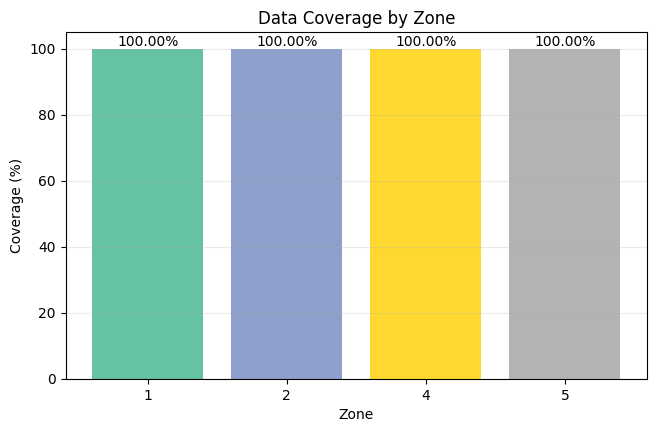

统计解释：三个 Zone 的时间覆盖率范围为 100.00% 到 100.00%。覆盖率越接近 100%，说明时间序列越完整，后续异常检测越不容易受到时间缺口影响。


,zone,expected_records,observed_records,missing_records,coverage_pct
0,1,90720,90720,0,100.0
1,2,90720,90720,0,100.0
2,4,90720,90720,0,100.0
3,5,90720,90720,0,100.0


In [10]:
def eda_01_data_coverage(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (zone), group in df.groupby("zone"):
        expected = pd.date_range(ANALYSIS_START, ANALYSIS_END, freq="1min")
        observed = pd.DatetimeIndex(group["timestamp"].drop_duplicates().sort_values())
        rows.append({
            "zone": zone,
            "expected_records": len(expected),
            "observed_records": len(observed),
            "missing_records": len(expected.difference(observed)),
            "coverage_pct": len(observed) / len(expected) * 100,
        })
    coverage = pd.DataFrame(rows)
    save_table(coverage.round(4), "01_data_coverage.csv")

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar(coverage["zone"].astype(str), coverage["coverage_pct"], color=plt.cm.Set2(np.linspace(0, 1, len(coverage))))
    ax.set_title("Data Coverage by Zone")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Coverage (%)")
    ax.set_ylim(0, 105)
    for idx, row in coverage.iterrows():
        ax.text(idx, row["coverage_pct"] + 1, f"{row['coverage_pct']:.2f}%", ha="center")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("01_data_coverage.png")
    plt.show()

    min_cov = coverage["coverage_pct"].min()
    max_cov = coverage["coverage_pct"].max()
    print_cn(f"统计解释：三个 Zone 的时间覆盖率范围为 {min_cov:.2f}% 到 {max_cov:.2f}%。覆盖率越接近 100%，说明时间序列越完整，后续异常检测越不容易受到时间缺口影响。")
    return coverage

coverage_summary = eda_01_data_coverage(smoothed)
display(coverage_summary.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/02_missing_rate_by_zone.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/02_missing_rate_heatmap.png


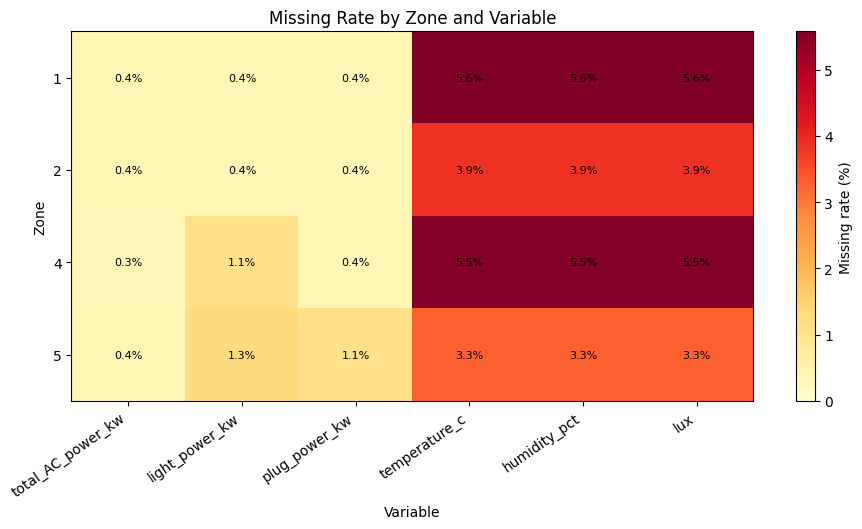

统计解释：最高缺失率出现在 Zone 1 的 temperature_c，缺失率为 5.58%。若该缺失来自传感器不存在，应视为结构性缺失，而不是运行异常。


,zone,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux
0,1,0.3505,0.3549,0.3549,5.5765,5.5765,5.5765
1,2,0.3505,0.3549,0.3527,3.8624,3.8624,3.8624
2,4,0.3450,1.1067,0.3616,5.5060,5.5060,5.5060
3,5,0.3505,1.2743,1.1067,3.2870,3.2870,3.2870


In [11]:
def eda_02_missing_rate(df: pd.DataFrame) -> pd.DataFrame:
    missing = df.groupby("zone")[VALUE_COLUMNS].apply(lambda x: x.isna().mean() * 100).round(4).reset_index()
    save_table(missing, "02_missing_rate_by_zone.csv")

    plot_data = missing.set_index("zone")[VALUE_COLUMNS]
    fig, ax = plt.subplots(figsize=(11, 4.8))
    im = ax.imshow(plot_data.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(1, np.nanmax(plot_data.values)))
    ax.set_title("Missing Rate by Zone and Variable")
    ax.set_xlabel("Variable")
    ax.set_ylabel("Zone")
    ax.set_xticks(range(len(plot_data.columns)))
    ax.set_xticklabels(plot_data.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index)
    for i in range(plot_data.shape[0]):
        for j in range(plot_data.shape[1]):
            ax.text(j, i, f"{plot_data.iloc[i, j]:.1f}%", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="Missing rate (%)")
    save_current_figure("02_missing_rate_heatmap.png")
    plt.show()

    highest = missing.melt(id_vars="zone", var_name="variable", value_name="missing_pct").sort_values("missing_pct", ascending=False).iloc[0]
    print_cn(f"统计解释：最高缺失率出现在 Zone {int(highest['zone'])} 的 {highest['variable']}，缺失率为 {highest['missing_pct']:.2f}%。若该缺失来自传感器不存在，应视为结构性缺失，而不是运行异常。")
    return missing

missing_rate_summary = eda_02_missing_rate(smoothed)
display(missing_rate_summary.head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/03_duplicate_check.csv
Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/03_duplicate_check.png


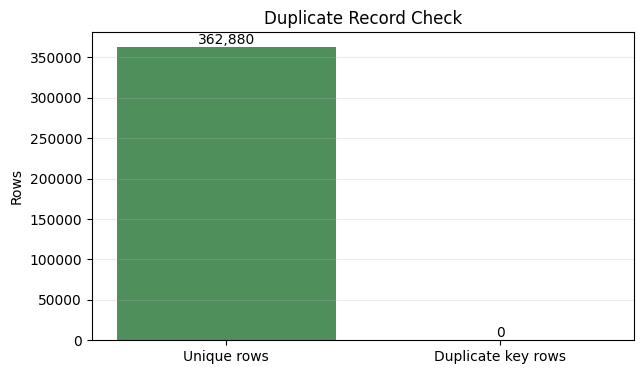

统计解释：以 timestamp + floor + zone 作为复合主键，重复记录数为 0，重复率为 0.0000%。重复率为 0 表示样本之间没有主键冲突。


,rows,key_columns,duplicate_key_rows,duplicate_rate_pct
0,362880,"timestamp, floor, zone",0,0.0


In [12]:
def eda_03_duplicate_check(df: pd.DataFrame) -> pd.DataFrame:
    duplicate_count = int(df.duplicated(KEY_COLUMNS).sum())
    summary = pd.DataFrame([{
        "rows": len(df),
        "key_columns": ", ".join(KEY_COLUMNS),
        "duplicate_key_rows": duplicate_count,
        "duplicate_rate_pct": duplicate_count / len(df) * 100 if len(df) else 0,
    }])
    save_table(summary.round(4), "03_duplicate_check.csv")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(["Unique rows", "Duplicate key rows"], [len(df) - duplicate_count, duplicate_count], color=["#4f8f5b", "#b94d4d"])
    ax.set_title("Duplicate Record Check")
    ax.set_ylabel("Rows")
    ax.grid(axis="y", alpha=0.25)
    for i, v in enumerate([len(df) - duplicate_count, duplicate_count]):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
    save_current_figure("03_duplicate_check.png")
    plt.show()

    print_cn(f"统计解释：以 timestamp + floor + zone 作为复合主键，重复记录数为 {duplicate_count:,}，重复率为 {summary.loc[0, 'duplicate_rate_pct']:.4f}%。重复率为 0 表示样本之间没有主键冲突。")
    return summary

duplicate_check_summary = eda_03_duplicate_check(smoothed)
display(duplicate_check_summary.round(4).head(20))

## Data Processing / Model Preparation

Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/00_raw_vs_15min_rolling_mean.png


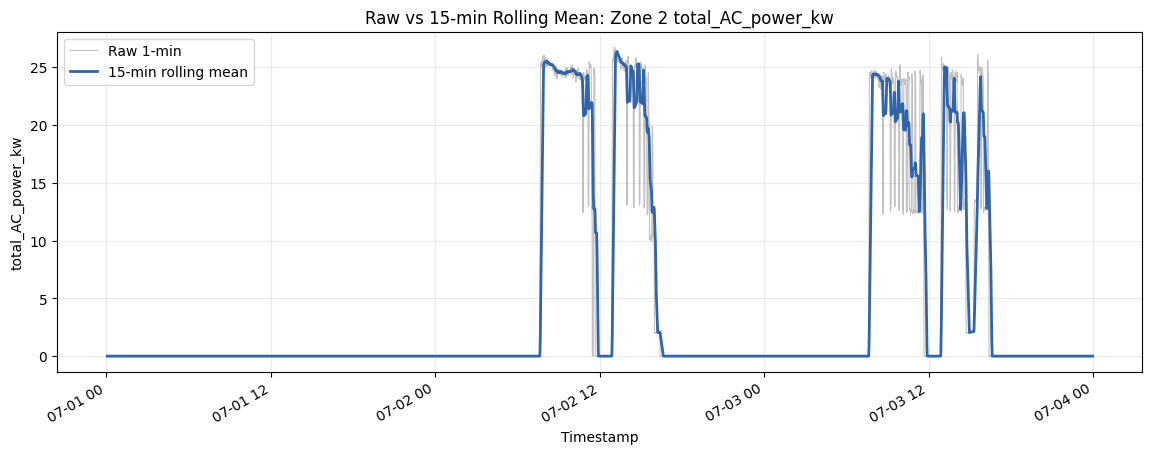

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/00_raw_vs_15min_rolling_mean_stats.csv
统计解释：Zone 2 的 total_AC_power_kw 经 15 分钟 rolling mean 后，标准差从 8.8017 降至 8.5311，说明平滑处理降低了短时噪声，更适合作为异常检测的稳定输入。


,zone,variable,raw_std,rolling_std,std_reduction_pct,raw_mean,rolling_mean
0,2,total_AC_power_kw,8.8017,8.5311,3.0748,4.2077,4.2116


In [13]:
def eda_00_raw_vs_rolling_mean(df: pd.DataFrame, zone: int = 2, variable: str = "total_AC_power_kw", days: int = 3) -> pd.DataFrame:
    smooth_col = f"{variable}_rolling_mean_{ROLLING_WINDOW_RECORDS}min"
    start = df["timestamp"].min()
    end = start + pd.Timedelta(days=days)
    subset = df[(df["zone"] == zone) & (df["timestamp"] >= start) & (df["timestamp"] < end)].copy()

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(subset["timestamp"], subset[variable], label="Raw 1-min", linewidth=0.8, alpha=0.45, color="#777777")
    ax.plot(subset["timestamp"], subset[smooth_col], label=f"{ROLLING_WINDOW_RECORDS}-min rolling mean", linewidth=2.0, color="#3264a8")
    ax.set_title(f"Raw vs {ROLLING_WINDOW_RECORDS}-min Rolling Mean: Zone {zone} {variable}")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel(variable)
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure("00_raw_vs_15min_rolling_mean.png")
    plt.show()

    stats = pd.DataFrame([{
        "zone": zone,
        "variable": variable,
        "raw_std": subset[variable].std(),
        "rolling_std": subset[smooth_col].std(),
        "std_reduction_pct": (1 - subset[smooth_col].std() / subset[variable].std()) * 100 if subset[variable].std() else np.nan,
        "raw_mean": subset[variable].mean(),
        "rolling_mean": subset[smooth_col].mean(),
    }])
    save_table(stats.round(4), "00_raw_vs_15min_rolling_mean_stats.csv")
    print_cn(f"统计解释：Zone {zone} 的 {variable} 经 {ROLLING_WINDOW_RECORDS} 分钟 rolling mean 后，标准差从 {stats.loc[0, 'raw_std']:.4f} 降至 {stats.loc[0, 'rolling_std']:.4f}，说明平滑处理降低了短时噪声，更适合作为异常检测的稳定输入。")
    return stats

rolling_comparison_stats = eda_00_raw_vs_rolling_mean(smoothed, zone=2, variable="total_AC_power_kw", days=3)
display(rolling_comparison_stats.round(4).head(20))

## Temporal Patterns

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/04_daily_total_power_by_zone.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/04_daily_total_power_by_zone.png


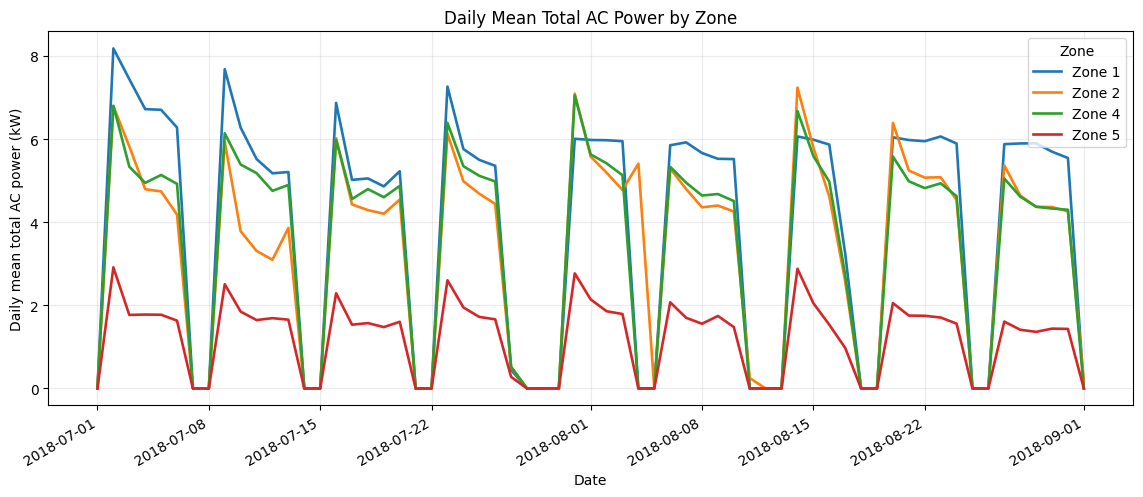

统计解释：日均总能耗最高的是 Zone 1，平均为 3.9533 kW。日均趋势可用于识别跨天持续偏高或偏低的异常模式。


,zone,date,daily_mean_total_AC_power_kw,daily_median_total_AC_power_kw,daily_std_total_AC_power_kw
0,1,2018-07-01,0.000000,0.0,0.000000
1,1,2018-07-02,8.184104,0.0,12.366095
2,1,2018-07-03,7.446424,0.0,11.573894
3,1,2018-07-04,6.723972,0.0,10.738194
4,1,2018-07-05,6.707944,0.0,10.713783
5,1,2018-07-06,6.281299,0.0,10.164435
6,1,2018-07-07,0.000000,0.0,0.000000
7,1,2018-07-08,0.000000,0.0,0.000000
8,1,2018-07-09,7.685993,0.0,11.969029
9,1,2018-07-10,6.278319,0.0,10.175896


In [14]:
def eda_04_daily_total_power_by_zone(df: pd.DataFrame) -> pd.DataFrame:
    daily = df.groupby(["zone", "date"]).agg(
        daily_mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
        daily_median_total_AC_power_kw=("total_AC_power_kw", "median"),
        daily_std_total_AC_power_kw=("total_AC_power_kw", "std"),
    ).reset_index()
    save_table(daily.round(4), "04_daily_total_power_by_zone.csv")

    fig, ax = plt.subplots(figsize=(14, 5.5))
    for zone, group in daily.groupby("zone"):
        ax.plot(pd.to_datetime(group["date"]), group["daily_mean_total_AC_power_kw"], label=f"Zone {zone}", linewidth=1.9)
    ax.set_title("Daily Mean Total AC Power by Zone")
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily mean total AC power (kW)")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure("04_daily_total_power_by_zone.png")
    plt.show()

    zone_means = daily.groupby("zone")["daily_mean_total_AC_power_kw"].mean().sort_values(ascending=False)
    print_cn(f"统计解释：日均总能耗最高的是 Zone {int(zone_means.index[0])}，平均为 {zone_means.iloc[0]:.4f} kW。日均趋势可用于识别跨天持续偏高或偏低的异常模式。")
    return daily

daily_total_power = eda_04_daily_total_power_by_zone(smoothed)
display(daily_total_power.head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/05_hourly_total_power_by_zone.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/05_hourly_total_power_by_zone.png


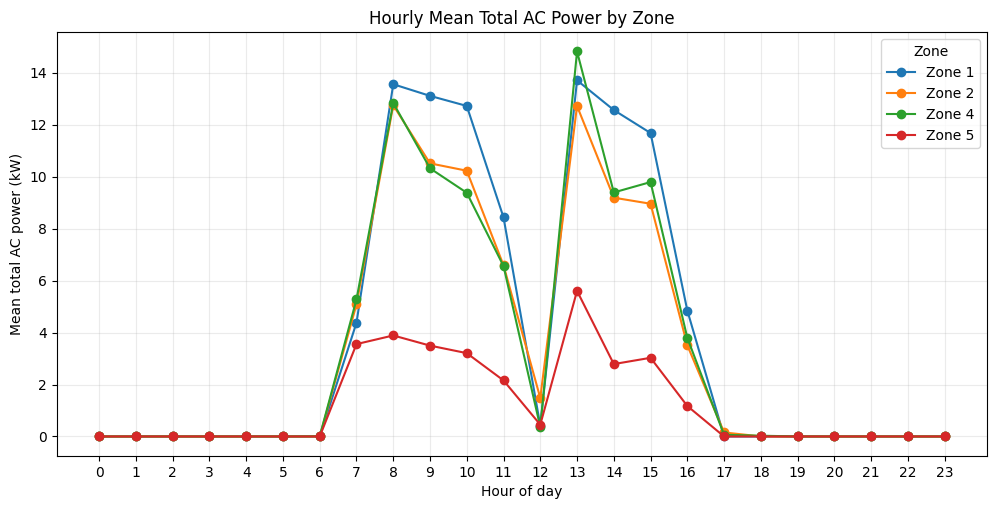

统计解释：小时均值最高点为 Zone 4 的 13:00，平均 total AC power 为 14.8217 kW。小时模式是建立正常用能 baseline 的核心依据。


,zone,hour,mean_total_AC_power_kw,median_total_AC_power_kw,std_total_AC_power_kw
0,1,0,0.000000,0.000,0.000000
1,1,1,0.000000,0.000,0.000000
2,1,2,0.000000,0.000,0.000000
3,1,3,0.000000,0.000,0.000000
4,1,4,0.000000,0.000,0.000000
5,1,5,0.000000,0.000,0.000000
6,1,6,0.000000,0.000,0.000000
7,1,7,4.378210,0.000,8.895361
8,1,8,13.560309,18.750,10.373250
9,1,9,13.112468,18.705,10.194121


In [15]:
def eda_05_hourly_total_power_by_zone(df: pd.DataFrame) -> pd.DataFrame:
    hourly = df.groupby(["zone", "hour"]).agg(
        mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
        median_total_AC_power_kw=("total_AC_power_kw", "median"),
        std_total_AC_power_kw=("total_AC_power_kw", "std"),
    ).reset_index()
    save_table(hourly.round(4), "05_hourly_total_power_by_zone.csv")

    fig, ax = plt.subplots(figsize=(12, 5.5))
    for zone, group in hourly.groupby("zone"):
        ax.plot(group["hour"], group["mean_total_AC_power_kw"], marker="o", label=f"Zone {zone}")
    ax.set_title("Hourly Mean Total AC Power by Zone")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Mean total AC power (kW)")
    ax.set_xticks(range(24))
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("05_hourly_total_power_by_zone.png")
    plt.show()

    peak = hourly.loc[hourly["mean_total_AC_power_kw"].idxmax()]
    print_cn(f"统计解释：小时均值最高点为 Zone {int(peak['zone'])} 的 {int(peak['hour'])}:00，平均 total AC power 为 {peak['mean_total_AC_power_kw']:.4f} kW。小时模式是建立正常用能 baseline 的核心依据。")
    return hourly

hourly_total_power = eda_05_hourly_total_power_by_zone(smoothed)
display(hourly_total_power.head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/06_weekday_vs_weekend.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/06_weekday_vs_weekend.png


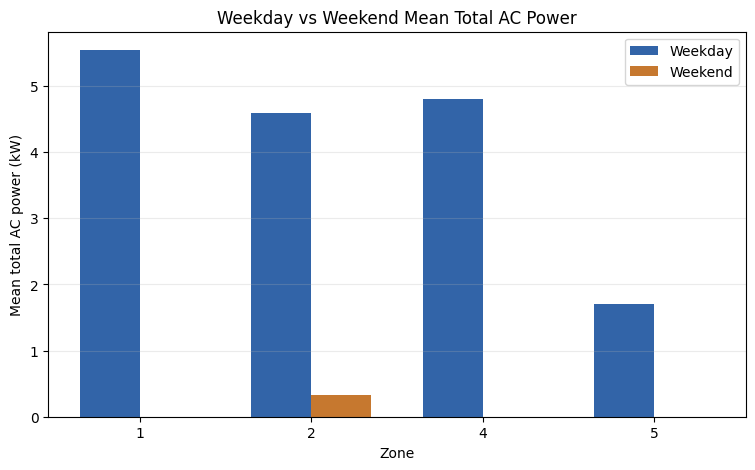

统计解释：工作日与周末差异最大的区域是 Zone 1，均值差为 5.5459 kW。该差异可用于识别非工作日异常用能。


,zone,day_type,mean_total_AC_power_kw,median_total_AC_power_kw,std_total_AC_power_kw,n
0,1,Weekday,5.5459,0.0,9.1475,64482
1,1,Weekend,0.0000,0.0,0.0000,25920
2,2,Weekday,4.5870,0.0,7.8392,64482
3,2,Weekend,0.3245,0.0,2.3087,25920
4,4,Weekday,4.8036,0.0,10.3016,64487
5,4,Weekend,0.0001,0.0,0.0014,25920
6,5,Weekday,1.7056,0.0,4.1492,64482
7,5,Weekend,0.0000,0.0,0.0026,25920


In [16]:
def eda_06_weekday_vs_weekend(df: pd.DataFrame) -> pd.DataFrame:
    summary = df.groupby(["zone", "day_type"]).agg(
        mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
        median_total_AC_power_kw=("total_AC_power_kw", "median"),
        std_total_AC_power_kw=("total_AC_power_kw", "std"),
        n=("total_AC_power_kw", "count"),
    ).reset_index()
    save_table(summary.round(4), "06_weekday_vs_weekend.csv")

    zones = sorted(df["zone"].unique())
    positions = np.arange(len(zones))
    width = 0.35
    weekday = summary[summary["day_type"] == "Weekday"].set_index("zone").reindex(zones)
    weekend = summary[summary["day_type"] == "Weekend"].set_index("zone").reindex(zones)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(positions - width / 2, weekday["mean_total_AC_power_kw"], width, label="Weekday", color="#3264a8")
    ax.bar(positions + width / 2, weekend["mean_total_AC_power_kw"], width, label="Weekend", color="#c6782f")
    ax.set_title("Weekday vs Weekend Mean Total AC Power")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Mean total AC power (kW)")
    ax.set_xticks(positions)
    ax.set_xticklabels(zones)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("06_weekday_vs_weekend.png")
    plt.show()

    merged = weekday[["mean_total_AC_power_kw"]].rename(columns={"mean_total_AC_power_kw": "weekday_mean"}).join(
        weekend[["mean_total_AC_power_kw"]].rename(columns={"mean_total_AC_power_kw": "weekend_mean"})
    )
    merged["weekday_minus_weekend"] = merged["weekday_mean"] - merged["weekend_mean"]
    strongest = merged["weekday_minus_weekend"].abs().idxmax()
    print_cn(f"统计解释：工作日与周末差异最大的区域是 Zone {int(strongest)}，均值差为 {merged.loc[strongest, 'weekday_minus_weekend']:.4f} kW。该差异可用于识别非工作日异常用能。")
    return summary

weekday_weekend_summary = eda_06_weekday_vs_weekend(smoothed)
display(weekday_weekend_summary.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/07_zone_hour_heatmap.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/07_zone_hour_heatmap.png


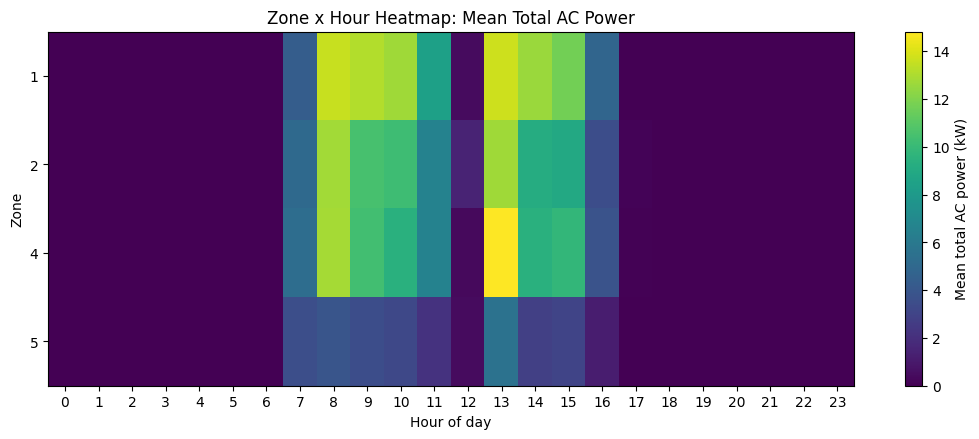

统计解释：热力图最高均值出现在 Zone 4 的 13:00。颜色块越亮表示该时段越接近高负载状态。


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
zone,,,,,,,,,,,,,,,,,,,,,,,,
1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,4.3782,13.5603,13.1125,12.7248,8.4337,0.4172,13.7106,12.5669,11.6815,4.8493,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000
2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,5.0830,12.7523,10.5143,10.2309,6.5890,1.4810,12.7232,9.1927,8.9595,3.5097,0.1547,0.0022,0.0000,0.0000,0.0000,0.0,0.0000
4,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001,0.006,5.2777,12.8383,10.3236,9.3819,6.5604,0.3668,14.8217,9.3944,9.7940,3.7956,0.0635,0.0283,0.0025,0.0001,0.0001,0.0,0.0001
5,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,3.5560,3.8887,3.4979,3.2082,2.1575,0.4536,5.6041,2.7870,3.0289,1.1735,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000


In [17]:
def eda_07_zone_hour_heatmap(df: pd.DataFrame) -> pd.DataFrame:
    heatmap = df.groupby(["zone", "hour"])["total_AC_power_kw"].mean().unstack("hour")
    save_table(heatmap.reset_index().round(4), "07_zone_hour_heatmap.csv")

    fig, ax = plt.subplots(figsize=(13, 4.6))
    im = ax.imshow(heatmap.values, aspect="auto", cmap="viridis")
    ax.set_title("Zone x Hour Heatmap: Mean Total AC Power")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Zone")
    ax.set_xticks(range(24))
    ax.set_xticklabels(range(24))
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)
    fig.colorbar(im, ax=ax, label="Mean total AC power (kW)")
    save_current_figure("07_zone_hour_heatmap.png")
    plt.show()

    max_zone, max_hour = np.unravel_index(np.nanargmax(heatmap.values), heatmap.shape)
    print_cn(f"统计解释：热力图最高均值出现在 Zone {int(heatmap.index[max_zone])} 的 {int(heatmap.columns[max_hour])}:00。颜色块越亮表示该时段越接近高负载状态。")
    return heatmap

zone_hour_heatmap = eda_07_zone_hour_heatmap(smoothed)
display(zone_hour_heatmap.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/08_two_month_overall_trend.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/08_two_month_overall_trend.png


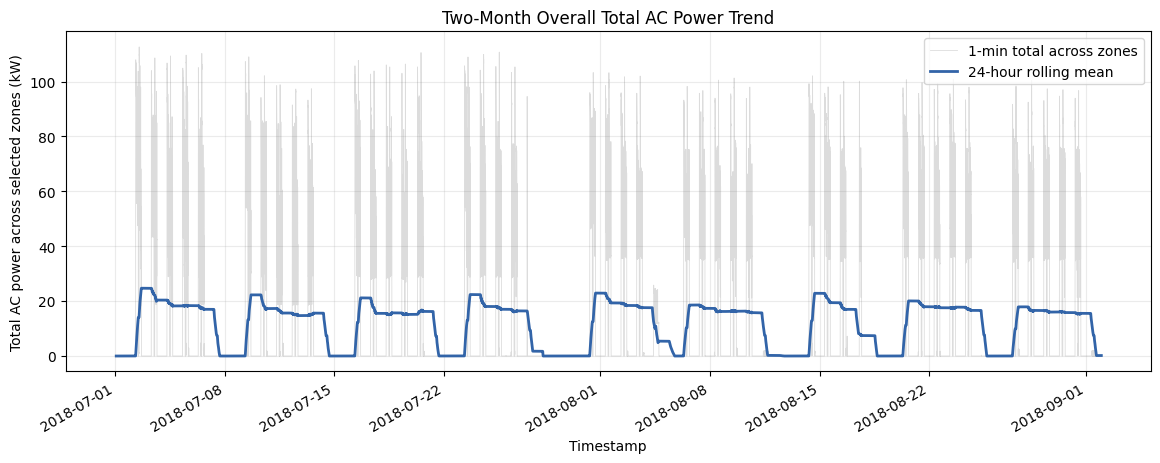

统计解释：首日平均总负载为 0.0000 kW，末日平均总负载为 0.1790 kW。两个月总体趋势可帮助判断是否存在长期漂移或季节性变化。


,timestamp,building_total_AC_power_kw,building_mean_total_AC_power_kw,building_total_AC_power_rolling_24h
0,2018-07-01 00:00:00,0.0,0.0,NaN
1,2018-07-01 00:01:00,0.0,0.0,NaN
2,2018-07-01 00:02:00,0.0,0.0,NaN
3,2018-07-01 00:03:00,0.0,0.0,NaN
4,2018-07-01 00:04:00,0.0,0.0,NaN
5,2018-07-01 00:05:00,0.0,0.0,NaN
6,2018-07-01 00:06:00,0.0,0.0,NaN
7,2018-07-01 00:07:00,0.0,0.0,NaN
8,2018-07-01 00:08:00,0.0,0.0,NaN
9,2018-07-01 00:09:00,0.0,0.0,NaN


In [18]:
def eda_08_two_month_overall_trend(df: pd.DataFrame) -> pd.DataFrame:
    overall = df.groupby("timestamp").agg(
        building_total_AC_power_kw=("total_AC_power_kw", "sum"),
        building_mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
    ).reset_index()
    overall["building_total_AC_power_rolling_24h"] = overall["building_total_AC_power_kw"].rolling(window=1440, min_periods=120).mean()
    save_table(overall.round(4), "08_two_month_overall_trend.csv")

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(overall["timestamp"], overall["building_total_AC_power_kw"], color="#777777", alpha=0.25, linewidth=0.6, label="1-min total across zones")
    ax.plot(overall["timestamp"], overall["building_total_AC_power_rolling_24h"], color="#3264a8", linewidth=2.0, label="24-hour rolling mean")
    ax.set_title("Two-Month Overall Total AC Power Trend")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Total AC power across selected zones (kW)")
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure("08_two_month_overall_trend.png")
    plt.show()

    start_mean = overall.head(1440)["building_total_AC_power_kw"].mean()
    end_mean = overall.tail(1440)["building_total_AC_power_kw"].mean()
    print_cn(f"统计解释：首日平均总负载为 {start_mean:.4f} kW，末日平均总负载为 {end_mean:.4f} kW。两个月总体趋势可帮助判断是否存在长期漂移或季节性变化。")
    return overall

two_month_trend = eda_08_two_month_overall_trend(smoothed)
display(two_month_trend.head(20))

## Energy Distribution

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/09_total_power_distribution_stats.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/09_total_power_distribution.png


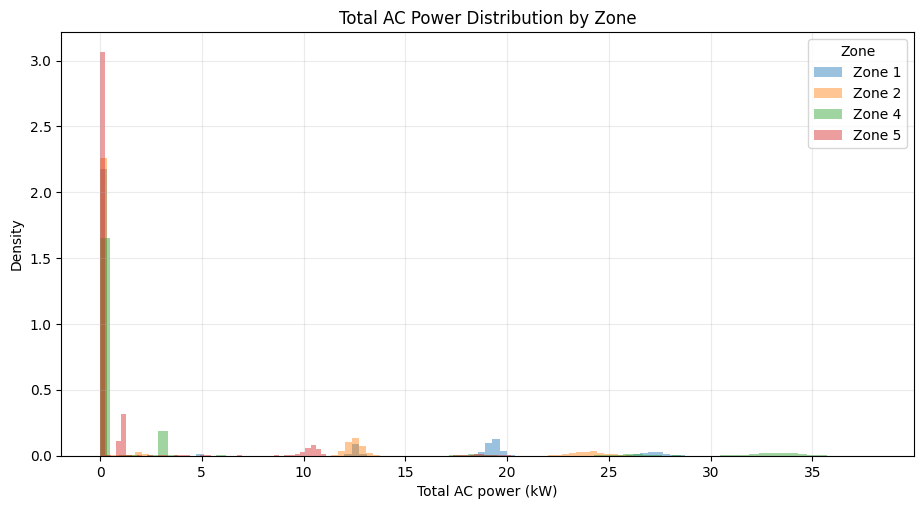

统计解释：偏度绝对值最大的是 Zone 5，skew=3.3637。正偏明显时，说明少量高功耗点拉长右尾，这类点常是异常检测关注对象。


,zone,count,mean,median,std,min,max,skew,cv,iqr_outlier_rate_pct
0,1,90402,3.9558,0.0,8.1225,0.0,29.10,1.7565,2.0533,0.0
1,2,90402,3.3649,0.0,7.0055,0.0,27.52,1.9505,2.0820,0.0
2,4,90407,3.4264,0.0,8.9675,0.0,38.08,2.6603,2.6171,0.0
3,5,90402,1.2166,0.0,3.5881,0.0,20.70,3.3637,2.9493,0.0


In [19]:
def eda_09_total_power_distribution(df: pd.DataFrame) -> pd.DataFrame:
    stats = df.groupby("zone")["total_AC_power_kw"].agg(["count", "mean", "median", "std", "min", "max", "skew"]).reset_index()
    stats["cv"] = df.groupby("zone")["total_AC_power_kw"].apply(coefficient_of_variation).values
    stats["iqr_outlier_rate_pct"] = df.groupby("zone")["total_AC_power_kw"].apply(iqr_outlier_rate).values
    save_table(stats.round(4), "09_total_power_distribution_stats.csv")

    fig, ax = plt.subplots(figsize=(11, 5.5))
    for zone, group in df.groupby("zone"):
        ax.hist(group["total_AC_power_kw"].dropna(), bins=80, alpha=0.45, density=True, label=f"Zone {zone}")
    ax.set_title("Total AC Power Distribution by Zone")
    ax.set_xlabel("Total AC power (kW)")
    ax.set_ylabel("Density")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("09_total_power_distribution.png")
    plt.show()

    skewed_zone = stats.iloc[stats["skew"].abs().idxmax()]
    print_cn(f"统计解释：偏度绝对值最大的是 Zone {int(skewed_zone['zone'])}，skew={skewed_zone['skew']:.4f}。正偏明显时，说明少量高功耗点拉长右尾，这类点常是异常检测关注对象。")
    return stats

total_power_distribution_stats = eda_09_total_power_distribution(smoothed)
display(total_power_distribution_stats.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/10_zone_boxplot_stats.csv
Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/10_zone_boxplot.png


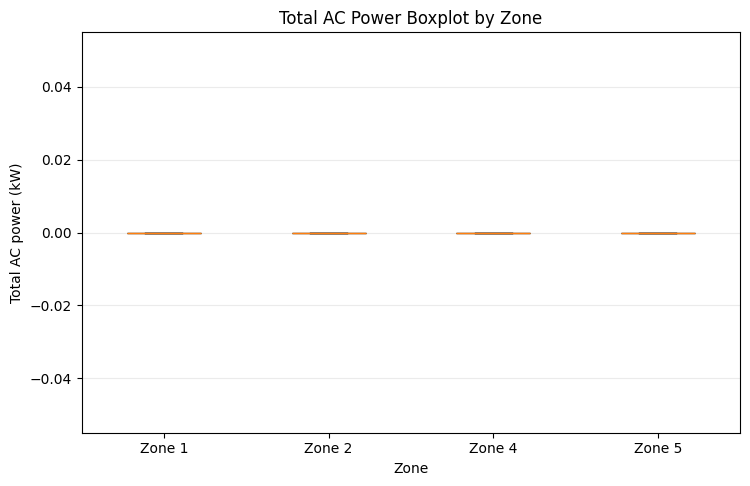

统计解释：IQR 最大的是 Zone 1，IQR=0.0000 kW，说明该区域正常波动范围更宽，建模时可考虑按 Zone 建立不同阈值。


,zone,q1,median,q3,iqr
0,1,0.0,0.0,0.0,0.0
1,2,0.0,0.0,0.0,0.0
2,4,0.0,0.0,0.0,0.0
3,5,0.0,0.0,0.0,0.0


In [20]:
def eda_10_zone_boxplot(df: pd.DataFrame) -> pd.DataFrame:
    zones = sorted(df["zone"].unique())
    data = [df.loc[df["zone"] == zone, "total_AC_power_kw"].dropna() for zone in zones]
    stats = df.groupby("zone")["total_AC_power_kw"].quantile([0.25, 0.5, 0.75]).unstack().rename(columns={0.25: "q1", 0.5: "median", 0.75: "q3"}).reset_index()
    stats["iqr"] = stats["q3"] - stats["q1"]
    save_table(stats.round(4), "10_zone_boxplot_stats.csv")

    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.boxplot(data, labels=[f"Zone {z}" for z in zones], showfliers=False, patch_artist=True, boxprops={"facecolor": "#d9e6f2"})
    ax.set_title("Total AC Power Boxplot by Zone")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Total AC power (kW)")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("10_zone_boxplot.png")
    plt.show()

    widest = stats.loc[stats["iqr"].idxmax()]
    print_cn(f"统计解释：IQR 最大的是 Zone {int(widest['zone'])}，IQR={widest['iqr']:.4f} kW，说明该区域正常波动范围更宽，建模时可考虑按 Zone 建立不同阈值。")
    return stats

zone_boxplot_stats = eda_10_zone_boxplot(smoothed)
display(zone_boxplot_stats.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/11_ac_light_plug_composition.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/11_ac_light_plug_composition.png


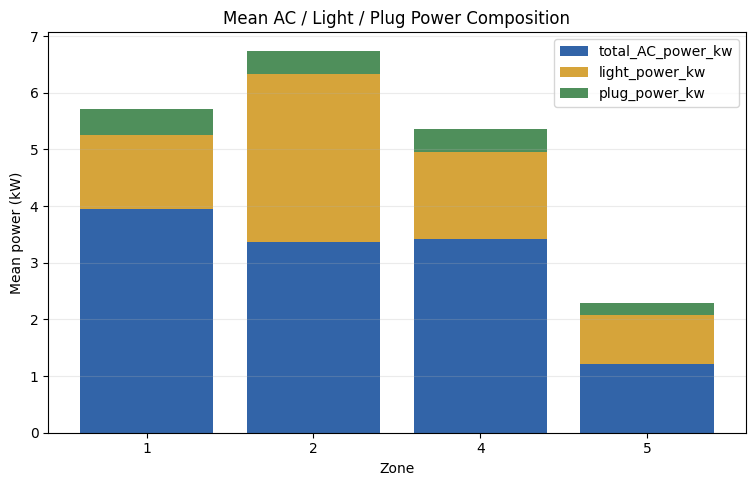

统计解释：Zone 1 的平均 AC 能耗最高。Floor 6 的 Zone 1、2、4、5 均有 AC meter，其中多 AC meter 的区域已先聚合为单一 total_AC_power_kw，因此不同 Zone 可以在同一特征结构下比较。


,zone,component,mean_power_kw
0,1,total_AC_power_kw,3.9558
1,2,total_AC_power_kw,3.3649
2,4,total_AC_power_kw,3.4264
3,5,total_AC_power_kw,1.2166
4,1,light_power_kw,1.2963
5,2,light_power_kw,2.9644
6,4,light_power_kw,1.5273
7,5,light_power_kw,0.8537
8,1,plug_power_kw,0.4567
9,2,plug_power_kw,0.4011


In [21]:
def eda_11_ac_light_plug_composition(df: pd.DataFrame) -> pd.DataFrame:
    composition = df.groupby("zone")[COMPONENT_POWER_COLUMNS].mean().reset_index()
    composition_long = composition.melt(id_vars="zone", var_name="component", value_name="mean_power_kw")
    save_table(composition_long.round(4), "11_ac_light_plug_composition.csv")

    plot_data = composition.set_index("zone")
    fig, ax = plt.subplots(figsize=(9, 5.2))
    bottom = np.zeros(len(plot_data))
    colors = {"total_AC_power_kw": "#3264a8", "light_power_kw": "#d6a43a", "plug_power_kw": "#4f8f5b"}
    for column in COMPONENT_POWER_COLUMNS:
        values = plot_data[column].fillna(0).values
        ax.bar(plot_data.index.astype(str), values, bottom=bottom, label=column, color=colors[column])
        bottom += values
    ax.set_title("Mean AC / Light / Plug Power Composition")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Mean power (kW)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("11_ac_light_plug_composition.png")
    plt.show()

    ac_mean = composition.set_index("zone")["total_AC_power_kw"]
    top_ac_zone = ac_mean.idxmax(skipna=True)
    print_cn(f"统计解释：Zone {int(top_ac_zone)} 的平均 AC 能耗最高。Floor 6 的 Zone 1、2、4、5 均有 AC meter，其中多 AC meter 的区域已先聚合为单一 total_AC_power_kw，因此不同 Zone 可以在同一特征结构下比较。")
    return composition_long

composition_summary = eda_11_ac_light_plug_composition(smoothed)
display(composition_summary.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/12_top_n_high_total_AC_power_records.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/12_top_n_high_total_AC_power_records.png


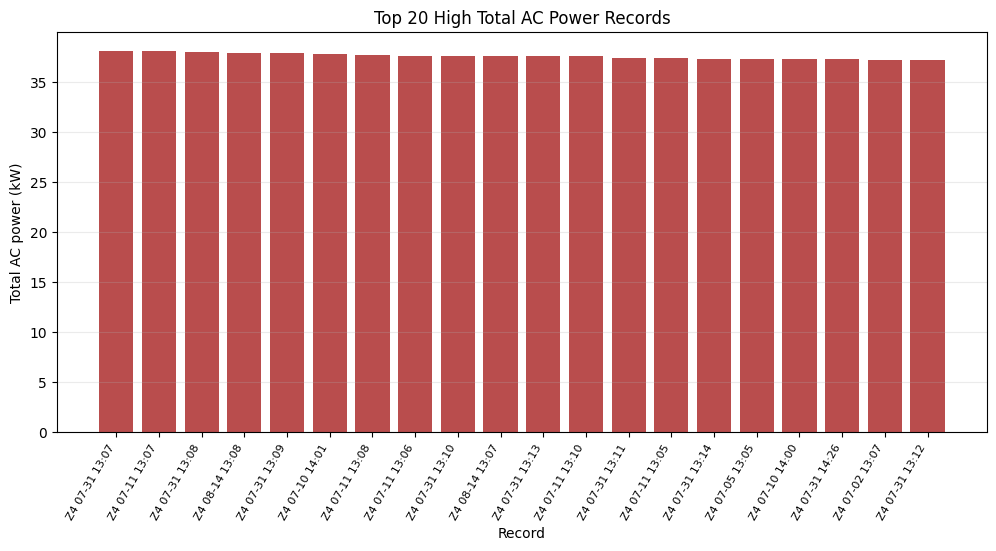

统计解释：Top 20 高功耗记录中，出现最多的是 Zone 4，共 20 条。这些记录可作为后续异常检测结果解释时的候选高 AC 负载样本。


,timestamp,floor,zone,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,day_type,hour
0,2018-07-31 13:07:00,6,4,38.08,4.17,1.27,26.62,59.44,28.0,Weekday,13
1,2018-07-11 13:07:00,6,4,38.06,4.01,1.66,24.68,65.32,43.0,Weekday,13
2,2018-07-31 13:08:00,6,4,37.99,4.31,1.24,26.42,59.40,29.0,Weekday,13
3,2018-08-14 13:08:00,6,4,37.92,4.32,2.19,26.17,57.86,31.0,Weekday,13
4,2018-07-31 13:09:00,6,4,37.86,4.33,2.27,26.23,59.37,29.0,Weekday,13
5,2018-07-10 14:01:00,6,4,37.77,4.56,1.23,22.43,70.75,42.0,Weekday,14
6,2018-07-11 13:08:00,6,4,37.70,4.02,1.65,24.53,65.16,43.0,Weekday,13
7,2018-07-11 13:06:00,6,4,37.63,4.01,1.61,NaN,NaN,NaN,Weekday,13
8,2018-07-31 13:10:00,6,4,37.60,4.33,1.60,26.50,59.35,29.0,Weekday,13
9,2018-08-14 13:07:00,6,4,37.57,4.34,1.53,26.36,57.88,31.0,Weekday,13


In [22]:
def eda_12_top_n_high_total_ac_power_records(df: pd.DataFrame, n: int = 20) -> pd.DataFrame:
    columns = ["timestamp", "floor", "zone", "total_AC_power_kw", "light_power_kw", "plug_power_kw", "temperature_c", "humidity_pct", "lux", "day_type", "hour"]
    top_records = df.sort_values("total_AC_power_kw", ascending=False)[columns].head(n).reset_index(drop=True)
    save_table(top_records.round(4), "12_top_n_high_total_AC_power_records.csv")

    fig, ax = plt.subplots(figsize=(12, 5.2))
    labels = top_records.apply(lambda row: f"Z{int(row['zone'])} {row['timestamp'].strftime('%m-%d %H:%M')}", axis=1)
    ax.bar(range(len(top_records)), top_records["total_AC_power_kw"], color="#b94d4d")
    ax.set_title(f"Top {n} High Total AC Power Records")
    ax.set_xlabel("Record")
    ax.set_ylabel("Total AC power (kW)")
    ax.set_xticks(range(len(top_records)))
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("12_top_n_high_total_AC_power_records.png")
    plt.show()

    zone_counts = top_records["zone"].value_counts().sort_index()
    dominant_zone = zone_counts.idxmax()
    print_cn(f"统计解释：Top {n} 高功耗记录中，出现最多的是 Zone {int(dominant_zone)}，共 {int(zone_counts.loc[dominant_zone])} 条。这些记录可作为后续异常检测结果解释时的候选高 AC 负载样本。")
    return top_records

top_high_total_ac_power_records = eda_12_top_n_high_total_ac_power_records(smoothed, n=20)
display(top_high_total_ac_power_records.head(20))

## Variable Relationships

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/13_correlation_heatmap.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/13_correlation_heatmap.png


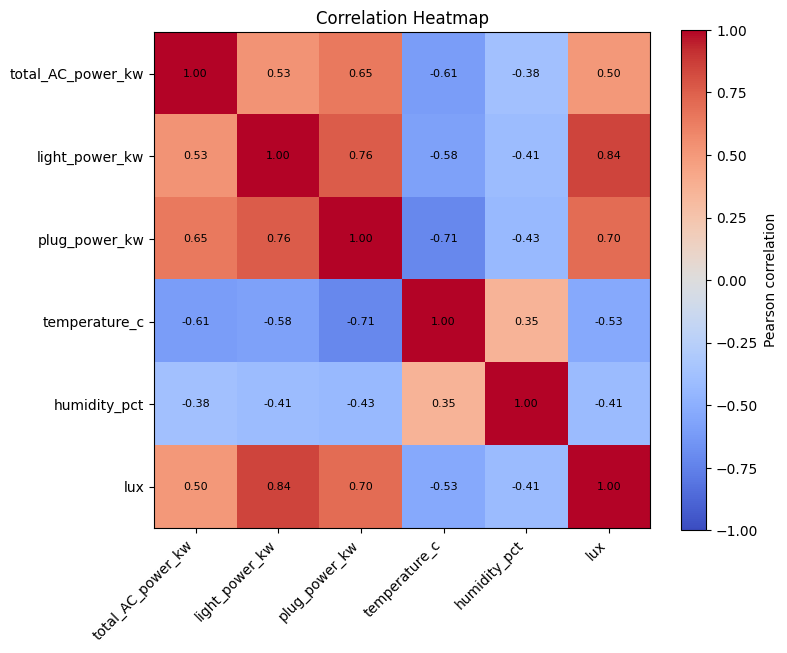

统计解释：绝对相关系数最高的变量对是 lux 与 light_power_kw，|r|=0.8439。高相关变量可能提供相似信息，建模时可检查是否存在特征冗余。


,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux
total_AC_power_kw,1.0000,0.5265,0.6458,-0.6081,-0.3771,0.5032
light_power_kw,0.5265,1.0000,0.7614,-0.5842,-0.4086,0.8439
plug_power_kw,0.6458,0.7614,1.0000,-0.7127,-0.4334,0.7024
temperature_c,-0.6081,-0.5842,-0.7127,1.0000,0.3538,-0.5339
humidity_pct,-0.3771,-0.4086,-0.4334,0.3538,1.0000,-0.4149
lux,0.5032,0.8439,0.7024,-0.5339,-0.4149,1.0000


In [23]:
def eda_13_correlation_heatmap(df: pd.DataFrame) -> pd.DataFrame:
    corr = df[VALUE_COLUMNS].corr(numeric_only=True)
    save_table(corr.reset_index().rename(columns={"index": "variable"}).round(4), "13_correlation_heatmap.csv")

    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_title("Correlation Heatmap")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.index)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    save_current_figure("13_correlation_heatmap.png")
    plt.show()

    corr_pairs = corr.where(~np.eye(corr.shape[0], dtype=bool)).stack().abs().sort_values(ascending=False)
    top_pair = corr_pairs.index[0]
    print_cn(f"统计解释：绝对相关系数最高的变量对是 {top_pair[0]} 与 {top_pair[1]}，|r|={corr_pairs.iloc[0]:.4f}。高相关变量可能提供相似信息，建模时可检查是否存在特征冗余。")
    return corr

correlation_matrix = eda_13_correlation_heatmap(smoothed)
display(correlation_matrix.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/14_temperature_vs_total_ac_power_stats.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/14_temperature_vs_total_ac_power.png


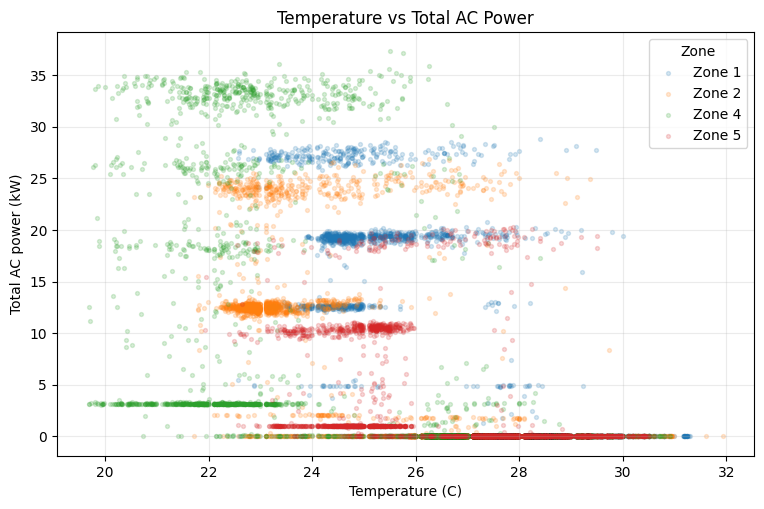

统计解释：Temperature 与 Total AC Power 相关性最强的是 Zone 1，Pearson r=-0.6944，完整样本数为 85,661。相关系数接近 0 表示线性关系较弱。


,zone,pearson_r,n_complete
0,1,-0.6944,85661
1,2,-0.6858,87216
2,4,-0.5933,85725
3,5,-0.4892,87738


In [24]:
def eda_14_temperature_vs_total_ac_power(df: pd.DataFrame, sample_size: int = 25000) -> pd.DataFrame:
    subset = df[["zone", "temperature_c", "total_AC_power_kw"]].dropna()
    if len(subset) > sample_size:
        subset = subset.sample(sample_size, random_state=42)

    stats = df.groupby("zone").apply(lambda g: g[["temperature_c", "total_AC_power_kw"]].corr().iloc[0, 1]).reset_index(name="pearson_r")
    stats["n_complete"] = df.groupby("zone").apply(lambda g: g[["temperature_c", "total_AC_power_kw"]].dropna().shape[0]).values
    save_table(stats.round(4), "14_temperature_vs_total_ac_power_stats.csv")

    fig, ax = plt.subplots(figsize=(9, 5.5))
    for zone, group in subset.groupby("zone"):
        ax.scatter(group["temperature_c"], group["total_AC_power_kw"], s=8, alpha=0.18, label=f"Zone {zone}")
    ax.set_title("Temperature vs Total AC Power")
    ax.set_xlabel("Temperature (C)")
    ax.set_ylabel("Total AC power (kW)")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("14_temperature_vs_total_ac_power.png")
    plt.show()

    strongest = stats.loc[stats["pearson_r"].abs().idxmax()]
    print_cn(f"统计解释：Temperature 与 Total AC Power 相关性最强的是 Zone {int(strongest['zone'])}，Pearson r={strongest['pearson_r']:.4f}，完整样本数为 {int(strongest['n_complete']):,}。相关系数接近 0 表示线性关系较弱。")
    return stats

temperature_total_ac_power_stats = eda_14_temperature_vs_total_ac_power(smoothed)
display(temperature_total_ac_power_stats.round(4).head(20))

Saved table: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/eda_tables/15_lux_vs_light_power_stats.csv


Saved figure: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures/15_lux_vs_light_power.png


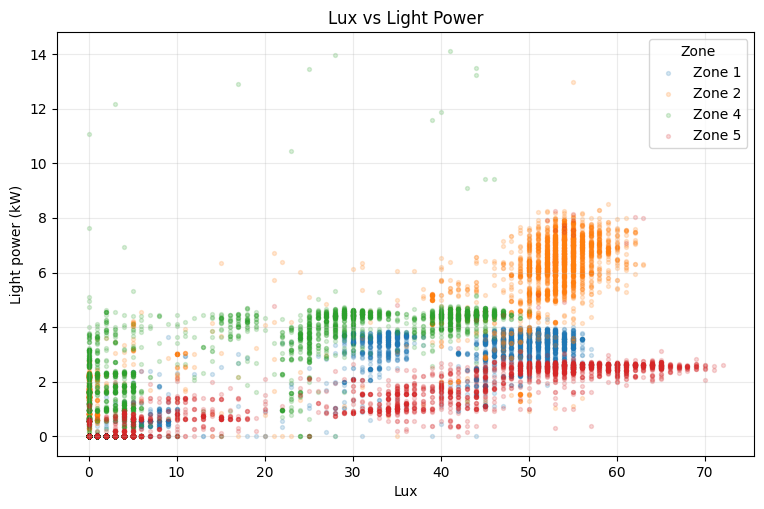

统计解释：Lux 与 Light Power 相关性最强的是 Zone 2，Pearson r=0.9659，完整样本数为 87,208。该图可检验照度变化是否与照明能耗同步。


,zone,pearson_r,n_complete
0,1,0.9580,85652
1,2,0.9659,87208
2,4,0.8632,85082
3,5,0.9470,86924


In [25]:
def eda_15_lux_vs_light_power(df: pd.DataFrame, sample_size: int = 25000) -> pd.DataFrame:
    subset = df[["zone", "lux", "light_power_kw"]].dropna()
    if len(subset) > sample_size:
        subset = subset.sample(sample_size, random_state=42)

    stats = df.groupby("zone").apply(lambda g: g[["lux", "light_power_kw"]].corr().iloc[0, 1]).reset_index(name="pearson_r")
    stats["n_complete"] = df.groupby("zone").apply(lambda g: g[["lux", "light_power_kw"]].dropna().shape[0]).values
    save_table(stats.round(4), "15_lux_vs_light_power_stats.csv")

    fig, ax = plt.subplots(figsize=(9, 5.5))
    for zone, group in subset.groupby("zone"):
        ax.scatter(group["lux"], group["light_power_kw"], s=8, alpha=0.18, label=f"Zone {zone}")
    ax.set_title("Lux vs Light Power")
    ax.set_xlabel("Lux")
    ax.set_ylabel("Light power (kW)")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("15_lux_vs_light_power.png")
    plt.show()

    strongest = stats.loc[stats["pearson_r"].abs().idxmax()]
    print_cn(f"统计解释：Lux 与 Light Power 相关性最强的是 Zone {int(strongest['zone'])}，Pearson r={strongest['pearson_r']:.4f}，完整样本数为 {int(strongest['n_complete']):,}。该图可检验照度变化是否与照明能耗同步。")
    return stats

lux_light_power_stats = eda_15_lux_vs_light_power(smoothed)
display(lux_light_power_stats.round(4).head(20))

## 9. Final Validation

In [26]:
def final_validation(df: pd.DataFrame) -> pd.DataFrame:
    summary = pd.DataFrame([{
        "final_dataset": FINAL_DATASET.name,
        "rows": len(df),
        "columns": len(df.columns),
        "floor": FLOOR,
        "zones": ",".join(map(str, sorted(df["zone"].unique()))),
        "min_timestamp": df["timestamp"].min(),
        "max_timestamp": df["timestamp"].max(),
        "key_columns": ", ".join(KEY_COLUMNS),
        "duplicate_key_rows": int(df.duplicated(KEY_COLUMNS).sum()),
        "rolling_window_records": ROLLING_WINDOW_RECORDS,
        "rolling_min_periods": ROLLING_MIN_PERIODS,
        "figure_count": len(list(FIGURE_DIR.glob("*.png"))),
        "eda_table_count": len(list(TABLE_DIR.glob("*.csv"))),
    }])
    summary.to_csv(OUTPUT_DIR / "13_final_validation_summary.csv", index=False)
    return summary

validation_summary = final_validation(smoothed)
display(validation_summary.head(20))
print("Main output:", FINAL_DATASET)
print("Preview:", OUTPUT_DIR / "floor6_zone1245_cleaned_smoothed_2018_jul01_sep01_preview.csv")
print("Figures:", FIGURE_DIR)
print("EDA tables:", TABLE_DIR)

,final_dataset,rows,columns,floor,zones,min_timestamp,max_timestamp,key_columns,duplicate_key_rows,rolling_window_records,rolling_min_periods,figure_count,eda_table_count
0,floor6_zone1245_cleaned_smoothed_2018_jul01_se...,362880,29,6,"1,2,4,5",2018-07-01,2018-09-01 23:59:00,"timestamp, floor, zone",0,15,5,20,20


Main output: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/floor6_zone1245_cleaned_smoothed_2018_jul01_sep01.csv.gz
Preview: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/floor6_zone1245_cleaned_smoothed_2018_jul01_sep01_preview.csv
Figures: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log Analysis/outputs/floor6_zone1245_2018_jul01_sep01_total_ac_eda/figures
EDA tables: /Users/yonglijiang/Documents/Adelaide University/AU Course/AU Course - 2026 Semester 2/Industry Research Project/Artificial Intelligence for Smart-Building Log A

## 10. Notes for Anomaly Detection

最终建模表采用复合主键：

```text
timestamp + floor + zone
```

建议后续 anomaly detection 使用 rolling mean 后的稳定特征作为主输入，并保留原始变量用于解释异常点。Floor 6 的 Zone 1、2、4、5 均有 AC meter；其中 Zone 4 的 `total_AC_power_kw` 来自多个 AC meter 的区域级求和。如果训练 AC-specific model，可以直接使用这些 Zone 的 `total_AC_power_kw`。